# 04. Multi-Round Strategy Ablations, Monte Carlo Risk & Manual Challenge Models

This notebook benchmarks our standalone production submissions (`traders/round1`–`traders/round5`) strictly on held-out out-of-sample sessions and calibrated/stressed Monte Carlo engines alongside ex-ante Round 1–5 Manual Challenge models:
1. **Round 1 Out-of-Sample Replay (`Day 0`, Official `±80` Limits)**: Progression from `NoOpBaseline` and `SymmetricMarketMaker` through `InventorySkewedMarketMaker` to `Round1Submission` (`10,000`-anchor Osmium MM + `+80` Pepper Root carry).
2. **Rounds 2–5 OOS & Fill-Mode Sensitivity**: Comparing `conservative`, `queue_aware`, and `touch` matching across standalone `traders/round{2..5}/submission.py`: total-vol options without delta hedging (`R3`), strictly causal `Mark 14`/`Mark 55` prior-tick flow (`R4`), and volatility-scaled AS quoting with `MICROCHIP_CIRCLE` 50/100/150/200-tick lead-lag (`R5`).
3. **Manual Challenges (`R1–R5`)**: Ex-ante analytical models—Poisson Cognitive Hierarchy (`R2`), Bayesian two-bid screening (`R3`), exact BS/Rubinstein + 4/day discrete barrier with Day-15 min-variance hedging (`R4`), and finite-downside (`-92%`) KKT allocation (`R5`).

*Note: Algorithmic metrics reflect simulated historical replays and synthetic Monte Carlo suites; Manual Challenge metrics reflect ex-ante offline models—never live exchange portal placements.*

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from prosperity_toolkit.backtesting.engine import BacktestEngine
from prosperity_toolkit.backtesting.metrics import PerformanceMetrics
from prosperity_toolkit.backtesting.replay import build_snapshots_from_dataframes
from prosperity_toolkit.competition import (
    CompetitionStrategyAdapter,
    get_round_position_limits,
    load_competition_trader,
)
from prosperity_toolkit.data.loader import DataLoader
from prosperity_toolkit.execution.simulator import ExecutionSimulator
from prosperity_toolkit.strategies import (
    InventorySkewedMarketMaker,
    MarketMakingConfig,
    NoOpBaselineStrategy,
    SymmetricMarketMaker,
)

loader = DataLoader(data_root=root / "data")
oos_snaps = build_snapshots_from_dataframes(
    loader.load_day_prices(1, 0),
    loader.load_day_trades(1, 0),
)
limits = get_round_position_limits(1)
cfgs = [
    MarketMakingConfig(symbol="ASH_COATED_OSMIUM", position_limit=80, quote_size=25),
    MarketMakingConfig(symbol="INTARIAN_PEPPER_ROOT", position_limit=80, quote_size=25),
]

rows = []
qa_curves = {}
for mode in ("conservative", "queue_aware", "touch"):
    strats = [
        NoOpBaselineStrategy(),
        SymmetricMarketMaker(cfgs),
        InventorySkewedMarketMaker(cfgs),
        CompetitionStrategyAdapter(
            load_competition_trader(root / "traders" / "round1" / "submission.py"),
            name="Round1Submission",
        ),
    ]
    for strat in strats:
        sim = ExecutionSimulator(position_limits=limits, fill_mode=mode)
        res = BacktestEngine(simulator=sim).run(strat, oos_snaps)
        rets = np.diff(np.asarray(res.equity_curve, dtype=np.float64), prepend=0.0).tolist()
        blk_sr = PerformanceMetrics.calculate_block_sharpe(rets, block_size=1000)
        lat = round(strat.mean_latency_ms, 4) if isinstance(strat, CompetitionStrategyAdapter) else 0.0
        rows.append({
            "fill_mode": mode,
            "strategy": res.strategy_name,
            "pnl": round(res.total_pnl, 2),
            "max_dd": round(res.max_drawdown, 2),
            "ir_tick": round(res.sharpe_ratio, 5),
            "block_sharpe_1k": round(blk_sr, 3),
            "fills": len(res.fills),
            "latency_ms": lat,
        })
        if mode == "queue_aware" and res.strategy_name != "NoOpBaseline":
            qa_curves[res.strategy_name] = res.equity_curve

display(pd.DataFrame(rows))

,fill_mode,strategy,pnl,max_dd,ir_tick,block_sharpe_1k,fills,latency_ms
0,conservative,NoOpBaseline,0.0,0.0,0.00000,0.000,0,0.0000
1,conservative,SymmetricMM,21731.0,2455.0,0.02034,0.995,618,0.0000
2,conservative,InventorySkewedMM,8072.0,2959.0,0.01187,0.432,952,0.0000
3,conservative,Round1Submission,91098.0,1405.0,0.05444,9.278,712,0.0394
4,queue_aware,NoOpBaseline,0.0,0.0,0.00000,0.000,0,0.0000
5,queue_aware,SymmetricMM,21731.0,2455.0,0.02034,0.995,618,0.0000
6,queue_aware,InventorySkewedMM,8251.0,2743.0,0.01227,0.476,957,0.0000
7,queue_aware,Round1Submission,91098.0,1405.0,0.05444,9.278,712,0.0336
8,touch,NoOpBaseline,0.0,0.0,0.00000,0.000,0,0.0000
9,touch,SymmetricMM,30670.0,2986.0,0.02627,1.001,635,0.0000


## 1. Round 1 Equity Curves & Per-Asset Attribution (`Day 0`, `queue_aware`)

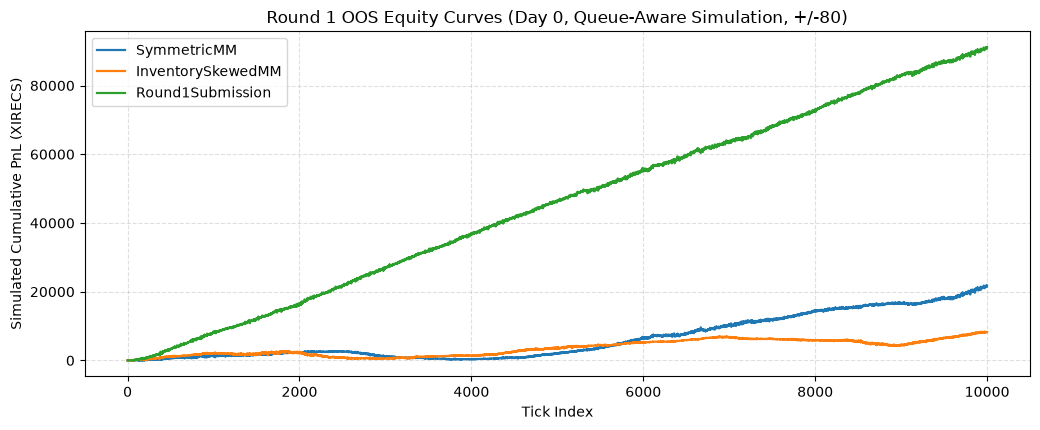

,symbol,simulated_pnl,end_position,total_fills,maker_fills,taker_fills
0,ASH_COATED_OSMIUM,11371.0,-69,524,246,278
1,INTARIAN_PEPPER_ROOT,79727.0,72,188,125,63


In [2]:
fig, ax = plt.subplots(figsize=(10.5, 4.4))
for label, curve in qa_curves.items():
    ax.plot(curve, label=label, linewidth=1.6)
ax.set_title("Round 1 OOS Equity Curves (Day 0, Queue-Aware Simulation, +/-80)")
ax.set_xlabel("Tick Index")
ax.set_ylabel("Simulated Cumulative PnL (XIRECS)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()

sim = ExecutionSimulator(position_limits=limits, fill_mode="queue_aware")
sub_res = BacktestEngine(simulator=sim).run(
    CompetitionStrategyAdapter(
        load_competition_trader(root / "traders" / "round1" / "submission.py"),
        name="Round1Submission",
    ),
    oos_snaps,
)
attr = []
for sym in ("ASH_COATED_OSMIUM", "INTARIAN_PEPPER_ROOT"):
    sym_fills = [f for f in sub_res.fills if f.symbol == sym]
    cash = sum(-(f.price * f.quantity) for f in sym_fills)
    pos = sum(f.quantity for f in sym_fills)
    last_mid = [s.get_book(sym).mid_price for s in oos_snaps if s.get_book(sym).mid_price is not None][-1]
    attr.append({
        "symbol": sym,
        "simulated_pnl": round(cash + pos * last_mid, 2),
        "end_position": pos,
        "total_fills": len(sym_fills),
        "maker_fills": sum(1 for f in sym_fills if f.fill_type.value == "MAKER"),
        "taker_fills": sum(1 for f in sym_fills if f.fill_type.value == "TAKER"),
    })
display(pd.DataFrame(attr))

## 2. Rounds 2–5 Held-Out Out-of-Sample & Monte Carlo Benchmarks

Comparing all standalone submissions side-by-side confirms clear structural performance:
- **Round 2 (`Day 1`, `±80`)**: Naive `SymmetricMM_80` loses `-20,294.50` riding `INTARIAN_PEPPER_ROOT` drift, whereas `Round2Submission` achieves `+94,209.00` OOS (`IR_tick = 0.05466`, `BlkSR_1k = 8.237`).
- **Round 3 (`Day 2`, `±200/300`)**: Holding OU+BS spot/calls (`VEV_4000..5500`) unhedged—rather than suffering wide-spread spot delta-hedging slippage—earns `+95,093.00` OOS.
- **Round 4 (`Day 3`, `±200/300`)**: Strictly causal prior-tick flow from `Mark 14` SELL and `Mark 55` BUY (`flow_weight = 1.5`) lifts OOS PnL to `+260,540.00` (`+11,153.50` above `Round3NoFlow` with lower MaxDD).
- **Round 5 (`Day 4`, `50 x ±10`)**: Volatility-scaled Avellaneda-Stoikov MM plus discrete `MICROCHIP_CIRCLE` 50/100/150/200 lag signals (`mc_beta = 0.16`) captures `+97,628.00` OOS at `0.55 ms/tick`, improving PnL `+2,215.50` over `Round5NoLeadLag` and achieving `1.66x` higher risk-adjusted `PnL/MaxDD` (`6.53` vs. `3.94`) than unfiltered `EmaSymmetricMM_All50`.

,round,split,fill_mode,strategy,total_pnl,ir_tick,block_sharpe_1k,pnl_to_max_dd,max_drawdown,total_fills,mean_latency_ms
20,R2,OOS,queue_aware,NoOpBaseline,0.0,0.000000,0.0000,0.0000,0.0,0,0.0000
21,R2,OOS,queue_aware,SymmetricMM_80,-20294.5,-0.021088,-0.8677,-0.9340,21729.5,709,0.0000
22,R2,OOS,queue_aware,InventorySkewedMM_80,8904.0,0.018122,0.7000,2.9459,3022.5,1022,0.0000
23,R2,OOS,queue_aware,DriftAwareQuoter_Pepper,7823.5,0.026046,0.6925,3.1207,2507.0,522,0.0000
24,R2,OOS,queue_aware,Round2Submission,94209.0,0.054659,8.2366,67.2441,1401.0,832,0.0281
46,R3,OOS,queue_aware,NoOpBaseline,0.0,0.000000,0.0000,0.0000,0.0,0,0.0000
47,R3,OOS,queue_aware,SymmetricSpotMM,-7160.0,-0.003882,-0.4549,-0.5026,14245.0,382,0.0000
48,R3,OOS,queue_aware,OptionsVolatilityContract,-1051.0,-0.000297,-0.0627,-0.0427,24608.5,89,0.0000
49,R3,OOS,queue_aware,Round3Submission,95093.0,0.005840,0.5730,1.2550,75774.0,2939,0.3249
66,R4,OOS,queue_aware,NoOpBaseline,0.0,0.000000,0.0000,0.0000,0.0,0,0.0000


,round,scenario,mean_pnl,std_pnl,median_pnl,var_95,cvar_95,prob_loss,prob_loss_ci95_upper,mean_ir_tick,worst_max_dd
0,2,Round2Submission_BaselineFlow,10966.54,3082.91,10783.75,6556.43,4548.00,0.000,0.0876,0.0764,3668.5
1,2,Round2Submission_MAFPlus25,12631.66,2982.79,13274.50,6491.52,5525.75,0.000,0.0876,0.0893,3481.0
2,2,Round2Submission_AdverseStress,5572.65,3417.73,5951.75,-789.07,-2163.50,0.100,0.2305,0.0299,9857.0
3,3,Round3Submission_CalibratedQA,29852.01,15334.10,30706.75,2010.05,-127.75,0.025,0.1288,0.0259,53851.5
4,3,Round3Submission_AdverseStress,13225.06,40180.23,22034.75,-53416.30,-91007.50,0.300,0.4543,0.0088,143306.0
5,4,Round4Submission_CalibratedQA,27562.95,21044.75,30545.50,-17878.60,-24536.25,0.125,0.2611,0.0244,75356.0
6,4,Round4Submission_AdverseStress,12042.42,38634.58,14055.50,-59763.20,-66346.50,0.275,0.4284,0.0082,96710.0
7,5,Round5Submission_11AssetRepPulseMC,15279.26,4141.61,14887.50,9767.02,8334.00,0.000,0.0876,0.1410,2651.5
8,5,Round5Submission_11AssetAdverseStress,12994.25,3294.20,12660.00,8720.42,8013.75,0.000,0.0876,0.1200,3946.0


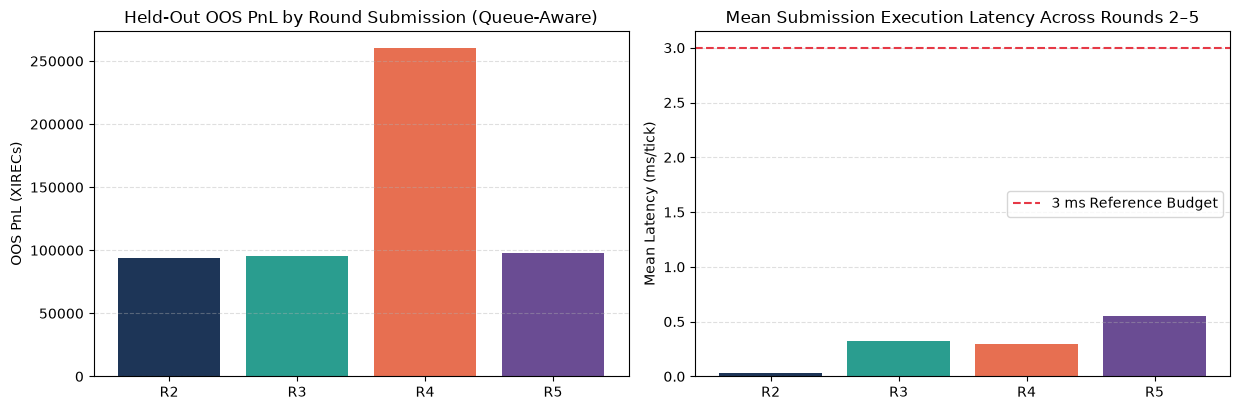

In [3]:
ab_frames = []
for rnum in (2, 3, 4, 5):
    df_r = pd.read_csv(root / "reports" / "tables" / f"r{rnum}_ablation_summary.csv")
    df_r.insert(0, "round", f"R{rnum}")
    ab_frames.append(df_r)

multi_ab = pd.concat(ab_frames, ignore_index=True)
oos_qa = multi_ab[(multi_ab["split"] == "OOS") & (multi_ab["fill_mode"] == "queue_aware")]
display(oos_qa)

mc_summary = pd.read_csv(root / "reports" / "tables" / "r2_to_r5_mc_risk_summary.csv")
display(mc_summary)

subs = oos_qa[oos_qa["strategy"].str.endswith("Submission")]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].bar(subs["round"], subs["total_pnl"], color=["#1d3557", "#2a9d8f", "#e76f51", "#6a4c93"])
axes[0].set_title("Held-Out OOS PnL by Round Submission (Queue-Aware)")
axes[0].set_ylabel("OOS PnL (XIRECs)")
axes[0].grid(True, axis="y", linestyle="--", alpha=0.4)

axes[1].bar(subs["round"], subs["mean_latency_ms"], color=["#1d3557", "#2a9d8f", "#e76f51", "#6a4c93"])
axes[1].axhline(3.0, color="#e63946", linestyle="--", label="3 ms Reference Budget")
axes[1].set_title("Mean Submission Execution Latency Across Rounds 2–5")
axes[1].set_ylabel("Mean Latency (ms/tick)")
axes[1].grid(True, axis="y", linestyle="--", alpha=0.4)
axes[1].legend()
fig.tight_layout()
plt.show()

## 3. Manual Challenges (Rounds 1–5) Verification

Inspecting `reports/tables/manual_challenges_summary.csv` records ex-ante offline optimal policies:
- **Round 1 (*An Intarian Welcome*)**: Uniform clearing under uncertain thresholds favors `(30, 65)` on `DRYLAND_FLAX` and `(20, 10)` on `EMBER_MUSHROOM`.
- **Round 2 (*Invest & Expand*)**: Under Poisson Cognitive Hierarchy (`tau = 1.5`), best-response progression selects Level-3 focal allocation (`15% Research / 43% Scale / 42% Speed`, EV `225,094.01`).
- **Round 3 (*Celestial Gardeners' Guild*)**: Bayesian screening over $\bar{b}_2 \sim \mathcal{N}(875, 15^2)$ sets `(775, 880)` (`76.00`/unit EV).
- **Round 4 (*Aether Crystal*)**: Closed-form BS/Rubinstein valuation plus 100k-path discrete `4/day` GBM KO pricing (`AC_45_KO = 0.2113` vs. `0.175` ask) with Day-15 mean-variance hedging (`AC_50_CO: -50, AC_40_BP: -50, AC_45_KO: +183, AC_50_C15: +53, AC_50_P15: +74`) cuts terminal standard deviation by `-70.1%`.
- **Round 5 (*Extra! Extra!*)**: Exact KKT simplex water-filling and quadratic variance control (`kappa = 3.0`) under finite `-92%` downside bounds (`Ashes of the Phoenix`) concentrates active bets in 5/9 goods (`857,400.00` KKT / `855,944.53` risk-adjusted net EV).

,round,challenge,scenario,parameter,optimal_action,expected_metric,metric_unit,assumption_note
0,R1,An Intarian Welcome,DRYLAND_FLAX (static book),"rest_clear=28, vol=150","bid px=29, qty=66",132.0000,XIRECs PnL,"Buyback=30, fee=0; shaded below tipping size"
1,R1,An Intarian Welcome,DRYLAND_FLAX (stochastic human demand),"fill_rate=0.96, crowd_N(45,22)","bid px=30, qty=65",68.1200,XIRECs Expected PnL,250 demand shocks around clearing threshold
2,R1,An Intarian Welcome,EMBER_MUSHROOM (stochastic human demand),"fill_rate=0.73, fee=0.10/unit","bid px=20, qty=10",9.8100,XIRECs Expected PnL,"Buyback=20, fee=0.10 (static opt=20.90)"
3,R2,Invest & Expand,Cognitive Hierarchy (L1 Best Response),speed_mult=0.757,"r=17.30%, s=53.20%, p=29.5%",305185.1000,XIRECs Net EV,Iterated best-response step L1 against field b...
4,R2,Invest & Expand,Cognitive Hierarchy (L2 Best Response),speed_mult=0.820,"r=15.65%, s=46.85%, p=37.5%",277759.7100,XIRECs Net EV,Iterated best-response step L2 against field b...
5,R2,Invest & Expand,Cognitive Hierarchy (L3 Best Response),speed_mult=0.818,"r=14.71%, s=43.29%, p=42.0%",246036.1000,XIRECs Net EV,Iterated best-response step L3 against field b...
6,R2,Invest & Expand,Ex-Ante Model Allocation (L3 Focal Equilibrium),speed_mult=0.761,"r=14.71%, s=43.29%, p=42.0%",225094.0100,XIRECs Net EV,Model-optimal discrete input (15%/43%/42%); L3...
7,R2,Invest & Expand,CH Mixture Stress Check (Unregularized QRE),speed_mult=0.803,"r=14.29%, s=41.71%, p=44.0%",226942.8000,XIRECs Net EV,Continuous L0-L3 best-response sensitivity upp...
8,R3,Celestial Gardeners Guild,Ex-Ante Bayesian Optimal Policy (avg_b2 ~ N(87...,"resale=920, exp_acc=0.768","b1=775, b2=880",76.0000,XIRECs EV/unit,Integrates asymmetric cubic cliff over cohort ...
9,R3,Celestial Gardeners Guild,Conservative Cohort Point Sensitivity (avg_b2=...,"resale=920, acc=0.765","b1=760, b2=860",83.1400,XIRECs EV/unit,Ex-ante lower-crowd aggressiveness sensitivity...


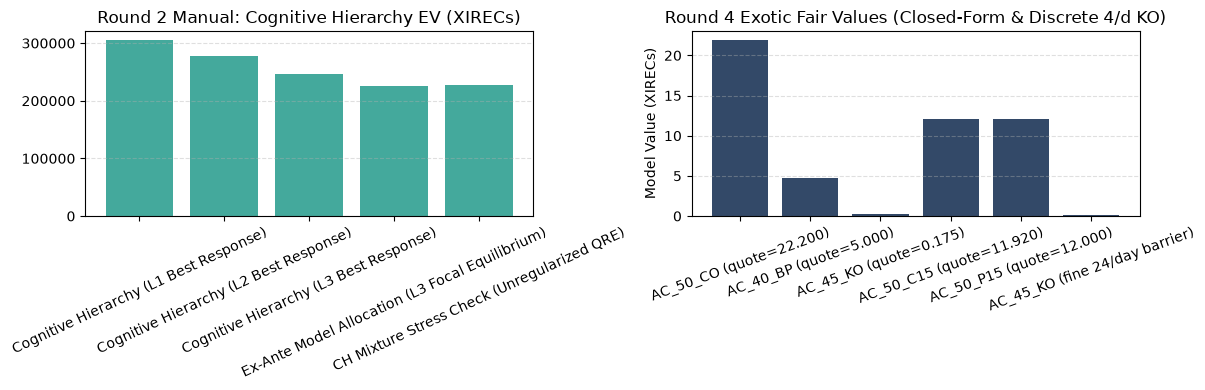

In [4]:
manual_df = pd.read_csv(root / "reports" / "tables" / "manual_challenges_summary.csv")
display(manual_df)

r2_rows = manual_df[manual_df["round"] == "R2"].copy()
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.0))
axes[0].bar(r2_rows["scenario"], r2_rows["expected_metric"], color="#2a9d8f", alpha=0.88)
axes[0].set_title("Round 2 Manual: Cognitive Hierarchy EV (XIRECs)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(True, axis="y", linestyle="--", alpha=0.4)

r4_contracts = manual_df[(manual_df["round"] == "R4") & (manual_df["metric_unit"].str.contains("Fair Value"))].copy()
axes[1].bar(r4_contracts["scenario"], r4_contracts["expected_metric"], color="#1d3557", alpha=0.9)
axes[1].set_title("Round 4 Exotic Fair Values (Closed-Form & Discrete 4/d KO)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].set_ylabel("Model Value (XIRECs)")
axes[1].grid(True, axis="y", linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()